# Residential load profiles: constrained Flow Matching

One sample is a 24-hour UTC residential consumption profile. A/B/C/D share one model and paired initial noise.

By default, Run All analyses the saved experiment named in `load_run.json`. Set `TRAIN_FROM_SCRATCH=True` to train a new model and evaluate it in a new directory. Result tables below are generated from that active run. The final technical report is supplied separately from the executable code.

Source: [MODERATE / Fluvius](https://zenodo.org/records/20525554). Values represent consumption per building; the landing page does not identify the physical unit. We use nonnegativity operationally for this nonnegative variable and report original CSV units. This does not establish a universal restriction for net-export measurements.


### Reading guide

Read each explanation before running the following code cell. The notebook is the
experiment narrative; imported Python modules implement the reusable mathematics.
See `CODE_GUIDE.md` for the file map, tensor shapes, units and execution order.
Flow time runs from 0 to 1 and is distinct from the 24 clock hours in a load profile.

**Experiment overview:** 24-dimensional profiles · 910/195/195 households in train/validation/test · 10 paired sampling seeds · 3 training seeds in the extension.


## Getting started · local Jupyter or Google Colab

**Read the saved outputs first.** They contain the completed experiment. Running all
cells refreshes the analysis with `TRAIN_FROM_SCRATCH = False`; no training is needed.

For **Google Colab**, upload the complete `flow_matching_project` folder to
**My Drive**, including the Python modules, manifests and `outputs/` directory.
Open this notebook in Colab and choose **Runtime → Run all**. The next cell mounts
Google Drive only when needed and locates the project. If you use another location,
set `PROJECT_DIRECTORY` to its full path. Uploading only the `.ipynb` is insufficient.
A CPU runtime is sufficient for analysing the saved experiments.

For **local Jupyter**, open the notebook from the project folder using the environment
in `README.md`. The setup preserves installed packages and installs only missing
analysis dependencies in Colab. Historical and validation versions are documented
in the two requirements files; runtime versions may differ in Colab.


In [1]:
# Locate the complete project before importing its local Python modules.
from pathlib import Path
import os
import sys
import importlib.util
import subprocess

PROJECT_DIRECTORY = ""  # Optional full path; leave empty for automatic detection.
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    try:
        IN_COLAB = importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        IN_COLAB = False

required = ("torus_project.py", "load_profile_project.py", "notebook_utils.py",
            "torus_run.json", "load_run.json", "outputs")

def is_project(path):
    """Recognise the supplied project by its modules and saved-run manifests."""
    return all((path / name).exists() for name in required)

candidates = ([Path(PROJECT_DIRECTORY).expanduser()] if PROJECT_DIRECTORY.strip()
              else [Path.cwd(), Path.cwd() / "flow_matching_project",
                    Path("/content/flow_matching_project"),
                    Path("/content/drive/MyDrive/flow_matching_project")])
if IN_COLAB and not any(is_project(p) for p in candidates) and not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")


project_root = next((p.resolve() for p in candidates if is_project(p)), None)
if project_root is None:
    raise FileNotFoundError(
        "Complete project folder not found. Upload the whole flow_matching_project "
        "folder to My Drive, or set PROJECT_DIRECTORY to its full path and rerun.")
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

packages = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
            "matplotlib": "matplotlib", "torch": "torch", "jinja2": "jinja2"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if not IN_COLAB:
        raise ImportError("Install requirements-audit.txt in your local environment.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Project ready:", project_root)


Project ready: /Users/mariadomarvieira/Desktop/flow_matching_project


In [2]:
# Select analysis or new training explicitly. A new training run receives a separate
# directory so historical measurements remain identifiable.
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from load_profile_project import (
    prepare_data,
    train_model,
    evaluate,
    plot_results,
    metrics,
    Velocity,
)
from supplementary_experiments import paired_table

from notebook_utils import COLORS, configure_plots, show_table, show_summary
configure_plots()
torch.set_num_threads(4)
TRAIN_FROM_SCRATCH = False
np.random.seed(42)
torch.manual_seed(42)
if TRAIN_FROM_SCRATCH:
    out = Path("outputs/load_profiles") / datetime.now().strftime(
        "run_%Y%m%d_%H%M%S_%f"
    )
    out.mkdir(parents=True)
else:
    out = Path(json.loads(Path("load_run.json").read_text())["run_dir"])
print("Active run:", out.as_posix(), "| Train new model:", TRAIN_FROM_SCRATCH)

Active run: outputs/load_profiles/run_20260928_190918_141268 | Train new model: False


## 1. Data, EDA and splitting

We check for unique, consecutive hourly timestamps and construct complete 24-hour UTC days. Local calendar conventions and daylight saving time changes are not modelled. We remove only days with nonfinite or negative values; we do not remove peaks or days that violate the proposed ramp limit.

Disjoint households: 70% training, 15% validation and 15% test, using seed 42. Days from the same household do not cross splits, but days are not independent observations and the splits share calendar dates. This test evaluates unseen households in the same year, rather than forecasting future years.

Normalization divides values by the global training standard deviation without centering. The ramp limit is the 99.5th percentile of absolute hourly differences in the training set. It is a proposed empirical limit, not a physical law; some real profiles may violate it.


Verified existing real dataset: /Users/mariadomarvieira/Desktop/flow_matching_project/fluvius_wide_format.csv


CSV shape: [8760, 1300]


,households,retained_days,removed_days
train,910,332150,0
validation,195,71175,0
test,195,71175,0


Scale: 0.8789365887641907 | Ramp threshold: 3.392000198364258
Missing/nonfinite: 0 | Negative: 0


,train,validation,test
count,7971600.0000,1708200.0000,1708200.0000
mean,0.5250,0.5666,0.5769
std,0.8789,0.9740,0.9817
min,0.0000,0.0000,0.0000
50%,0.2460,0.2520,0.2660
95%,2.0230,2.2030,2.1860
99%,4.1600,4.6180,4.4630
max,22.3050,15.6450,18.0040


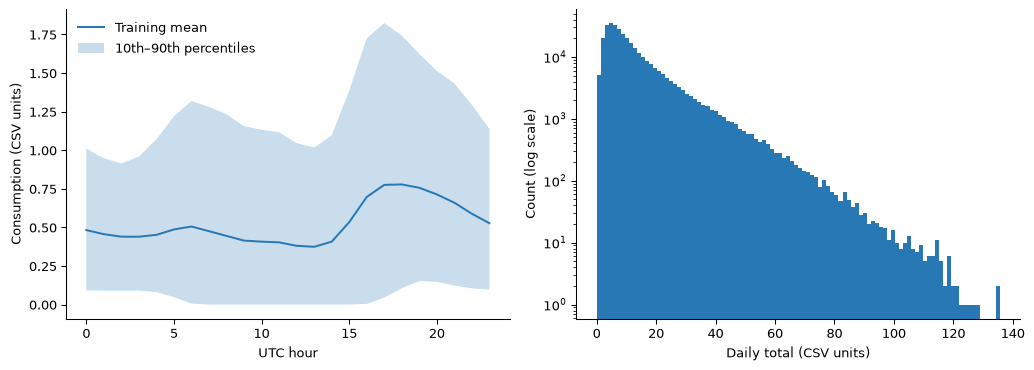

In [3]:
# Build complete household-days, verify provenance, and inspect training-only
# statistics. The raw arrays stay in CSV units; normalization occurs inside
# training.
from prepare_dataset import main as verify_dataset
verify_dataset()
arrays, info = prepare_data()
if TRAIN_FROM_SCRATCH:
    (out / "data_config.json").write_text(json.dumps(info, indent=2), encoding="utf-8")
else:
    recorded = json.loads((out / "data_config.json").read_text())
    assert (
        info["sha256"] == recorded["sha256"]
    ), "Dataset differs from the selected experiment"
    assert info["split_households"] == recorded["split_households"]
print("CSV shape:", info["shape"])
show_table(pd.DataFrame(info["counts"]).T, "Household-day split", precision=0)
print("Scale:", info["scale"], "| Ramp threshold:", info["ramp_threshold"])
print(
    "Missing/nonfinite:",
    info["nonfinite_values"],
    "| Negative:",
    info["negative_values"],
)
show_table(
    pd.DataFrame(
        {
            name: pd.Series(a.ravel()).describe(percentiles=[0.5, 0.95, 0.99])
            for name, a in arrays.items()
        }
    ), "Consumption statistics · original CSV units"
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train = arrays["train"]
axes[0].plot(range(24), train.mean(0), label="Training mean")
axes[0].fill_between(
    range(24),
    np.quantile(train, 0.1, axis=0),
    np.quantile(train, 0.9, axis=0),
    alpha=0.25,
    label="10th–90th percentiles",
)
axes[0].set(xlabel="UTC hour", ylabel="Consumption (CSV units)")
axes[0].legend()
axes[1].hist(train.sum(1), bins=100, log=True)
axes[1].set(xlabel="Daily total (CSV units)", ylabel="Count (log scale)")
fig.tight_layout()
fig.savefig(out / "eda.png", dpi=160)
plt.show()

## 2. Mathematical constraints

In the original space, $x_t\geq0$ and $|x_t-x_{t-1}|\leq R$ for t=2,…,24. We do not impose a ramp between the last and first hours of the day. In normalized space y=x/s, the limit is R/s.

We write the 70 inequalities as Gy−b≤0. B uses a gradient step on $\frac12\|\max(Gy-b,0)\|^2$: $y\leftarrow y-(0.3/9)G^T\max(Gy-b,0)$. The factor 9 bounds the squared norm of G; λ=0.3 is fixed before testing. This inequality version differs from the normalized equality correction used for the torus.

C/D use Euclidean projection onto the convex intersection via Dykstra's algorithm: the nonnegative orthant and two sets of disjoint hourly pairs. We check convergence and feasibility with an internal tolerance of 2e−6 in normalized space. If the algorithm does not converge, execution fails explicitly.


The three projection substeps have different roles: nonnegativity removes negative
hours, while the even/odd slabs enforce disjoint hourly differences. Dykstra's
correction vectors preserve the information needed to find the nearest point in
their intersection; this is stronger than repeatedly clipping until feasible.


In [4]:
# Evaluate the chosen ramp bound on actual data before interpreting generated
# feasibility. Excluded real behaviour remains part of the fidelity target.
# Real-data feasibility: important for interpreting the empirical constraint.
ramp = info["ramp_threshold"]
real_feasibility = []
for name, a in arrays.items():
    excess = np.maximum(np.abs(np.diff(a, axis=1)) - ramp, 0)
    real_feasibility.append(
        dict(
            split=name,
            feasible_fraction=float((excess.max(1) <= 1e-5).mean()),
            ramp_violation_fraction=float((excess > 1e-5).mean()),
            mean_ramp_excess=float(excess.mean()),
        )
    )
real_feasibility = pd.DataFrame(real_feasibility)
real_feasibility.to_csv(out / "real_feasibility.csv", index=False)
show_table(real_feasibility.set_index("split").assign(
    feasible_fraction=lambda f: 100 * f.feasible_fraction,
    ramp_violation_fraction=lambda f: 100 * f.ramp_violation_fraction
).rename(columns={"feasible_fraction": "Feasible days (%)",
                  "ramp_violation_fraction": "Violating ramps (%)",
                  "mean_ramp_excess": "Mean ramp excess"}),
    "Feasibility of real data · empirical bound, original CSV units")

,Feasible days (%),Violating ramps (%),Mean ramp excess
split,,,
train,93.5267,0.5000,0.0092
validation,91.5659,0.6890,0.0134
test,92.0632,0.6160,0.0127


## 3. Train or load one model

Linear Flow Matching: xₜ=(1−t)x₀+tx₁, target x₁−x₀, standard normal noise. MLP 25 → 256 × 4 (SiLU) → 24; 5,000 iterations, batch size 512, Adam 0.001, gradient clipping at 1. The checkpoint is selected by the lowest MSE on a fixed set of validation examples, evaluated every 250 iterations. The test set is not involved in normalization, threshold estimation or selection. This MSE-based selection is a simple baseline, not an exhaustive optimization of fidelity.


In [5]:
# Checkpoint selection uses fixed validation regression examples. Loading a
# checkpoint reproduces analysis without fitting another model.
if TRAIN_FROM_SCRATCH:
    model, history, selected_step = train_model(
        arrays["train"], arrays["validation"], info["scale"], out
    )
else:
    checkpoint = torch.load(out / "model.pt", map_location="cpu", weights_only=False)
    model = Velocity()
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    history = pd.read_csv(out / "training.csv")
    selected_step = checkpoint["selected_step"]
print("Selected checkpoint iteration:", selected_step)
show_table(history.set_index("step"), "Recorded training and fixed-validation MSE")

Selected checkpoint iteration: 5000


,train_loss,validation_loss
step,,
250,1.1380,1.2214
500,1.0500,1.1381
750,1.0023,1.0775
1000,0.8607,1.0550
1250,0.9764,1.0272
1500,0.9440,1.0267
1750,0.9287,1.0077
2000,0.8257,0.9929
2250,0.8333,0.9879


## 4. Compare A/B/C/D

2,000 samples, 100 Euler steps and 10 inference seeds. For each seed, all four methods start from the same noise and use the same model. D is the projection of A's result.

Feasibility: fraction of valid profiles, frequency and magnitude of nonnegativity/ramp violations, and mean number of violations per profile. Tolerance: max(1e−5, s×1e−5) in the original units.

Fidelity: sliced Wasserstein-1 across 128 fixed directions, errors in mean shape and hourly variability, Wasserstein distances for daily totals and peaks, and autocorrelation error (lags 1–6). Consumption-magnitude metrics use original CSV units; autocorrelation and its error are dimensionless. ACF excludes constant profiles and uses the day's sum of squared deviations as its denominator. Reference: test samples without filtering by the ramp constraint. The reference/reference comparison provides a scale for sampling error.

The 10 seeds measure generation/reference variability with a fixed model, not uncertainty across training runs or statistical confidence intervals.


In [6]:
# Evaluate new samples or read the selected run. Rebuild summaries from per-seed
# measurements so tables follow the active experiment.
if TRAIN_FROM_SCRATCH:
    frame, summary, illustration = evaluate(model, arrays, info, out)
    config = dict(
        n_samples=2000,
        n_steps=100,
        seeds=list(range(10)),
        sw_directions=128,
        sw_seed=2026,
        soft_strength=0.3,
        soft_gradient_divisor=9,
        projection_tolerance_normalized=2e-6,
        feasibility_tolerance=max(1e-5, info["scale"] * 1e-5),
        selected_step=selected_step,
    )
    (out / "experiment_config.json").write_text(json.dumps(config, indent=2))
else:
    config = json.loads((out / "experiment_config.json").read_text())
    frame = pd.read_csv(out / "metrics.csv")
    summary = frame.groupby("method")[
        [c for c in frame if c not in ("seed", "method")]
    ].agg(["mean", "std"])
    with np.load(out / "samples_seed_0.npz") as saved:
        illustration = (saved["reference"].copy(), {k: saved[k].copy() for k in "ABCD"})
show_summary(frame, {
    "mean_violations_per_profile": "Violations/day ↓", "feasible_fraction": "Feasible (%) ↑",
    "sliced_w1": "SW1 ↓", "daily_total_w1": "Daily-total W1 ↓"},
    "Primary residential comparison · mean ± sample SD across 10 sampling seeds",
    percentages=("feasible_fraction",))
show_summary(frame, {
    "mean_shape_rmse": "Shape RMSE ↓", "hourly_std_rmse": "Hourly SD RMSE ↓",
    "peak_w1": "Peak W1 ↓", "acf_mae": "ACF MAE ↓"},
    "Domain fidelity · original CSV units, except dimensionless ACF")
show_summary(frame, {
    "negative_hour_fraction": "Negative hours (%) ↓", "ramp_violation_fraction": "Violating ramps (%) ↓",
    "mean_lower_violation": "Mean negative excess ↓", "mean_ramp_excess": "Mean ramp excess ↓"},
    "Component-level violations · distinct from whole-profile feasibility",
    percentages=("negative_hour_fraction", "ramp_violation_fraction"))
baseline = pd.read_csv(out / "reference_metrics.csv").drop(columns="seed").agg(["mean", "std"]).T
show_table(baseline, "Reference/reference metrics · finite-sample comparison scale")


,Violations/day ↓,Feasible (%) ↑,SW1 ↓,Daily-total W1 ↓
Method,,,,
A,1.6011 ± 0.0410,45.14 ± 0.99,0.0622 ± 0.0039,0.6039 ± 0.1444
B,0.0977 ± 0.0066,94.80 ± 0.41,0.2853 ± 0.0117,7.8875 ± 0.3942
C,0.0000 ± 0.0000,100.00 ± 0.00,1.0225 ± 0.0160,30.3452 ± 0.4879
D,0.0000 ± 0.0000,100.00 ± 0.00,0.0656 ± 0.0038,0.6203 ± 0.1452


,Shape RMSE ↓,Hourly SD RMSE ↓,Peak W1 ↓,ACF MAE ↓
Method,,,,
A,0.0587 ± 0.0077,0.1426 ± 0.0229,0.0937 ± 0.0134,0.0086 ± 0.0020
B,0.3355 ± 0.0167,0.1592 ± 0.0267,0.3948 ± 0.0384,0.0134 ± 0.0034
C,1.2717 ± 0.0205,0.3407 ± 0.0323,1.4682 ± 0.0412,0.0397 ± 0.0035
D,0.0606 ± 0.0081,0.1455 ± 0.0213,0.1084 ± 0.0194,0.0081 ± 0.0020


,Negative hours (%) ↓,Violating ramps (%) ↓,Mean negative excess ↓,Mean ramp excess ↓
Method,,,,
A,6.17 ± 0.18,0.52 ± 0.04,0.0037 ± 0.0002,0.0068 ± 0.0007
B,0.04 ± 0.01,0.39 ± 0.03,1.19e-05 ± 4.70e-06,0.0017 ± 0.0002
C,0.00 ± 0.00,0.00 ± 0.00,0.0000 ± 0.0000,6.36e-10 ± 9.69e-11
D,0.00 ± 0.00,0.00 ± 0.00,0.0000 ± 0.0000,7.30e-10 ± 9.07e-11


,mean,std
feasible_fraction,0.9196,0.0073
negative_hour_fraction,0.0000,0.0000
ramp_violation_fraction,0.0063,0.0007
mean_violations_per_profile,0.1450,0.0155
mean_lower_violation,0.0000,0.0000
mean_ramp_excess,0.0127,0.0016
sliced_w1,0.0440,0.0033
mean_shape_rmse,0.0293,0.0055
hourly_std_rmse,0.0927,0.0173
peak_w1,0.0777,0.0156


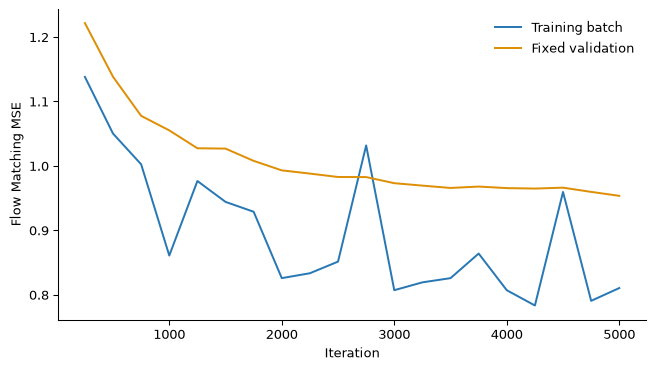

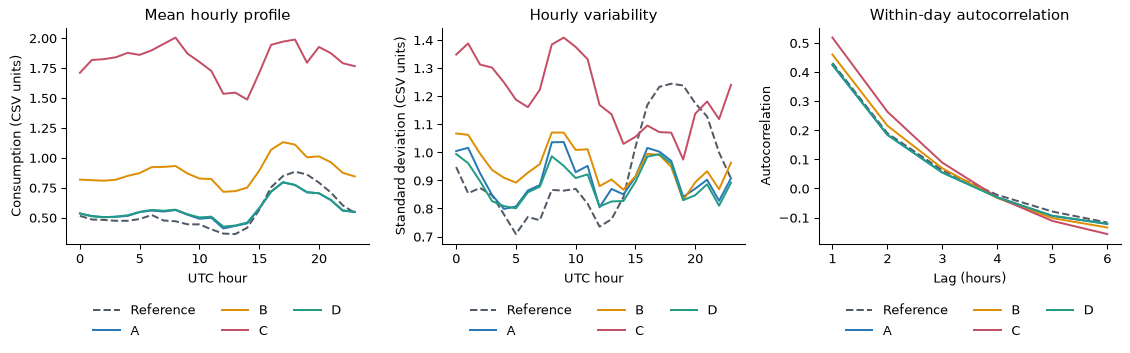

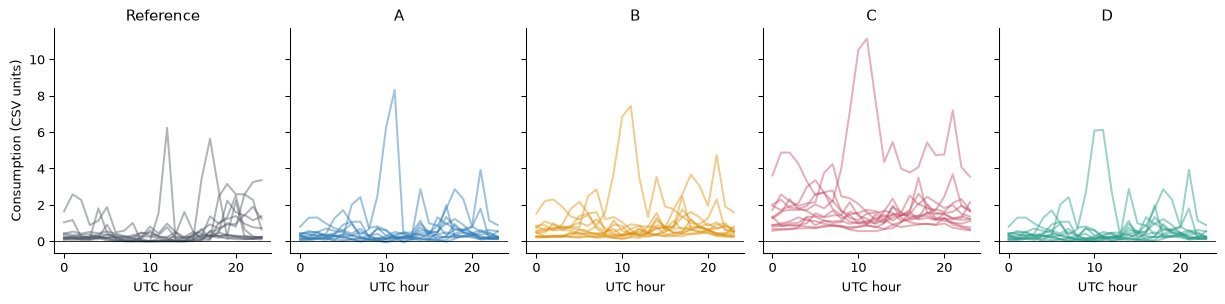

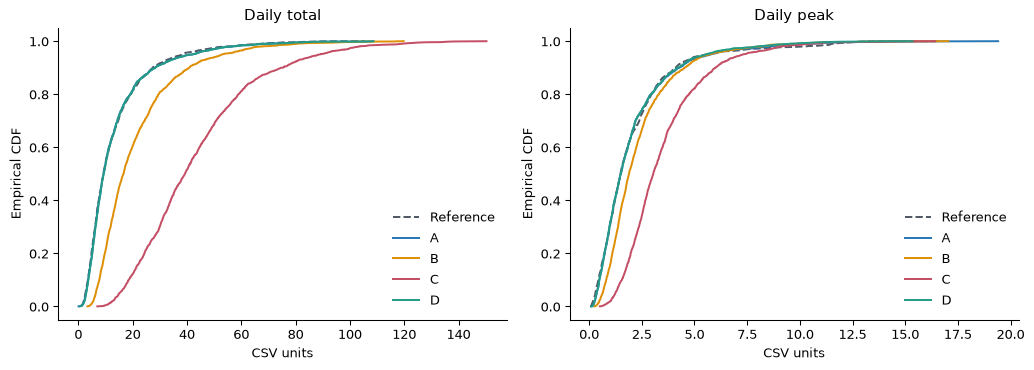

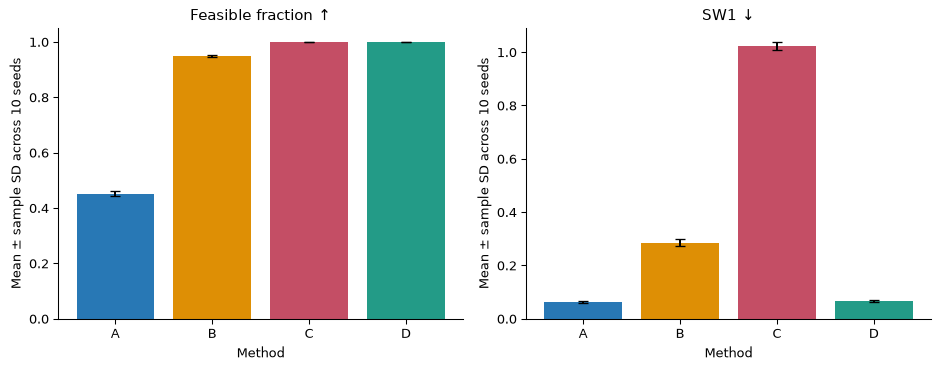

Results saved: /Users/mariadomarvieira/Desktop/flow_matching_project/outputs/load_profiles/run_20260928_190918_141268


In [7]:
# Visualize seed-0 profiles as examples and aggregate feasibility/SW1 over all
# sampling seeds. Examples are not selected to be representative.
plot_results(history, illustration, frame, out)
print("Results saved:", out.resolve())

## 5. Interpretation and limitations

Compare the results without assuming that D wins in the real application. An empirical ramp constraint may exclude real behaviour and create an unavoidable trade-off between feasibility and fidelity. We retain the full real distribution as the reference to reveal this effect.

Limitations: one year of data, households from the same geographical context, UTC days, no conditioning on season/household type, dependence between days, one training run in the primary comparison (three in the extension), one architecture, one threshold and one correction strength. Synthetic profiles do not, by themselves, provide formal privacy guarantees.

References: project documents `Project Proposal.pdf`, `References and Reading Guide to Project-1.pdf`; [MODERATE dataset](https://zenodo.org/records/20525554); Lipman et al., *Flow Matching for Generative Modeling*, ICLR 2023. A/B/C/D are simplified project strategies, not full reproductions of HardFlow or PCFM.


In [8]:
# Generate the final table and paired differences from the same frame used above.
# Avoid manually copied numbers that could outlive their experiment.
paired = paired_table(frame)
display(Markdown("### Paired SW1 differences relative to A (mean and sample SD)"))
show_table(paired.agg(["mean", "std"]).T,
           "Paired SW1 differences · positive means worse than A")
real_test = real_feasibility.loc[
    real_feasibility["split"] == "test", "feasible_fraction"
].iloc[0]
display(
    Markdown(
        f"Real test days violating the empirical constraint: **{100*(1-real_test):.2f}%**. "
        "Sampling-seed SD is not training uncertainty. Interpret all methods jointly in terms of feasibility and fidelity."
    )
)

### Paired SW1 differences relative to A (mean and sample SD)

,mean,std
B-A,0.2232,0.0115
C-A,0.9604,0.0159
D-A,0.0034,0.0009


Real test days violating the empirical constraint: **7.94%**. Sampling-seed SD is not training uncertainty. Interpret all methods jointly in terms of feasibility and fidelity.

## Supplementary experiments

The fixed main comparison above remains separate from the extension. `supplementary_experiments.py` runs a three-way **validation** ablation, records trajectories, and compares training seeds 42/43/44 over ten sampling seeds each. It does not tune parameters. The extension is descriptive follow-up after the original test results were seen.

A/B/C/D continue to share one model within each training seed. Between-training SD is calculated from the three model-level means, not from 30 observations treated as independent. Three models give only limited evidence of robustness.


Interpret the two feasibility columns separately: `active_feasible_fraction` checks
only the constraints used by that ablation, while `feasible_fraction` always checks
both original constraints. A ramp-only sample can therefore be feasible for the
ablation yet still contain negative values. The dashed trajectory curve is a
training interpolation diagnostic, not another trained generation method.


Supplementary run: outputs/supplementary/run_20260930_212353_028360


,B-A,C-A,D-A
training_seed,,,
42,0.2232,0.9604,0.0034
43,0.1656,0.7008,0.0013
44,0.1648,0.7876,0.0017


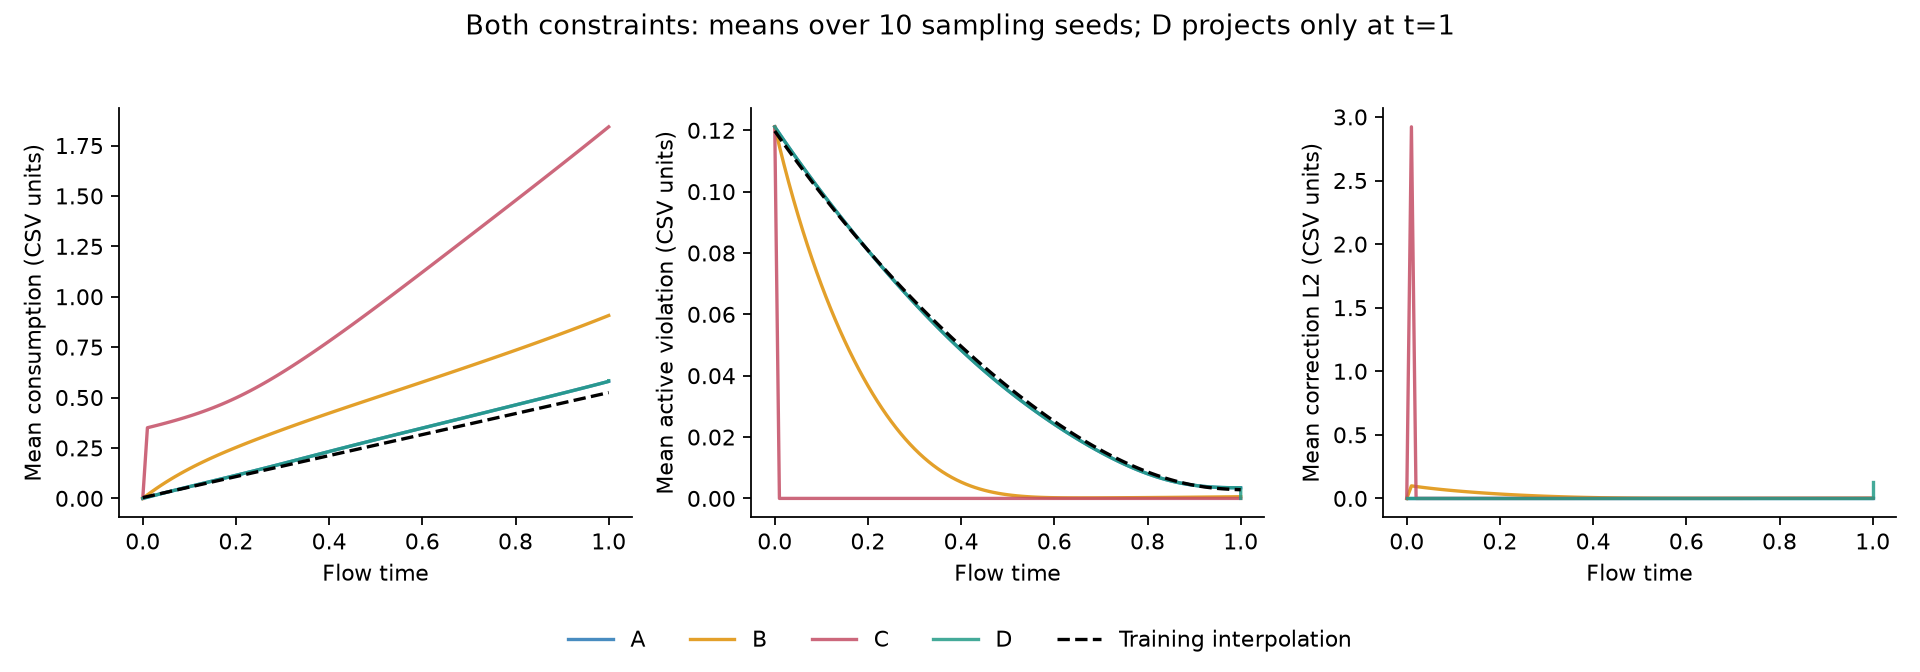

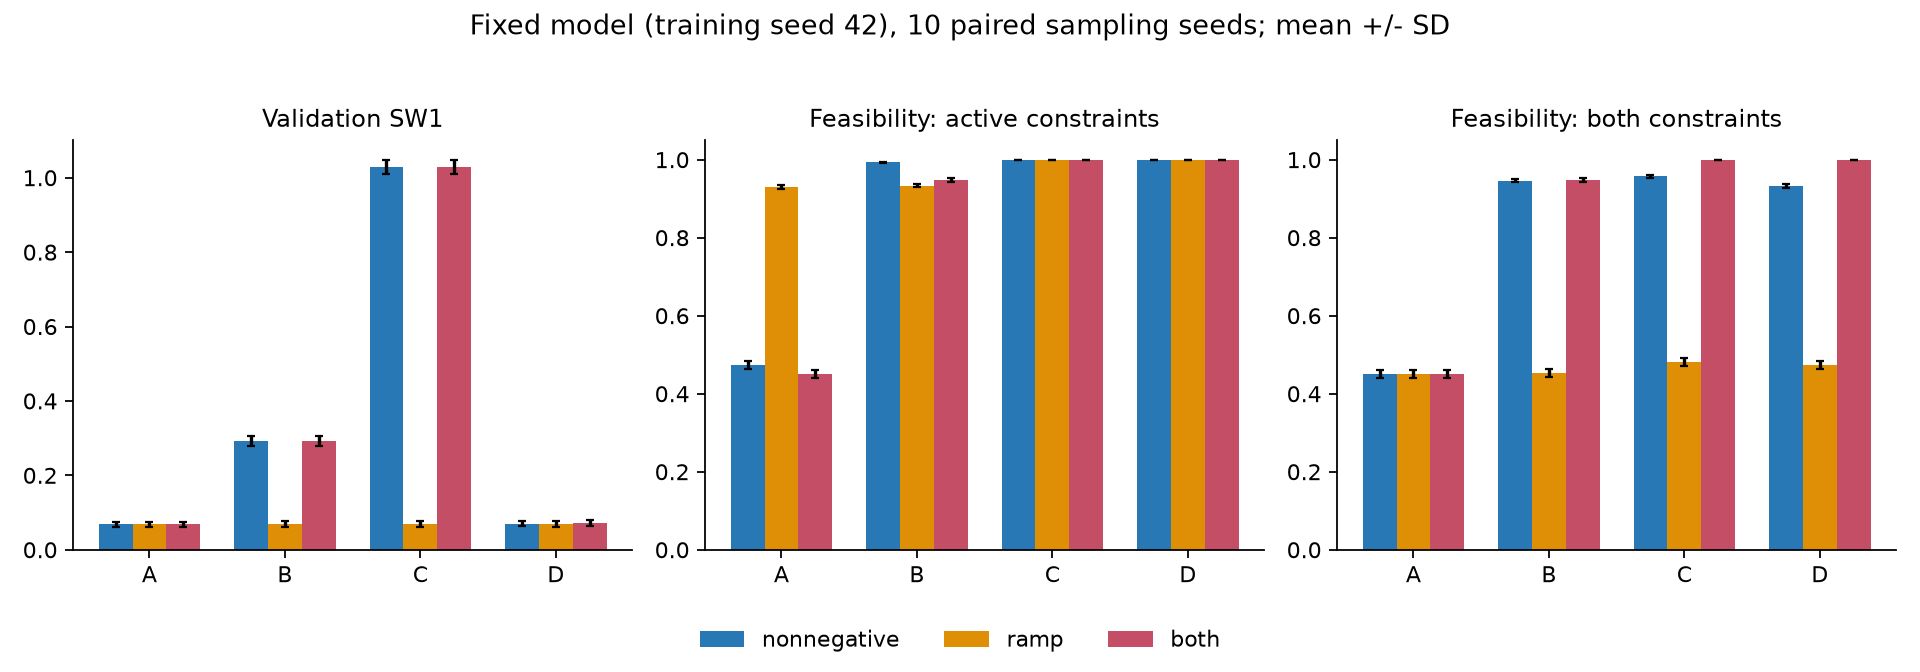

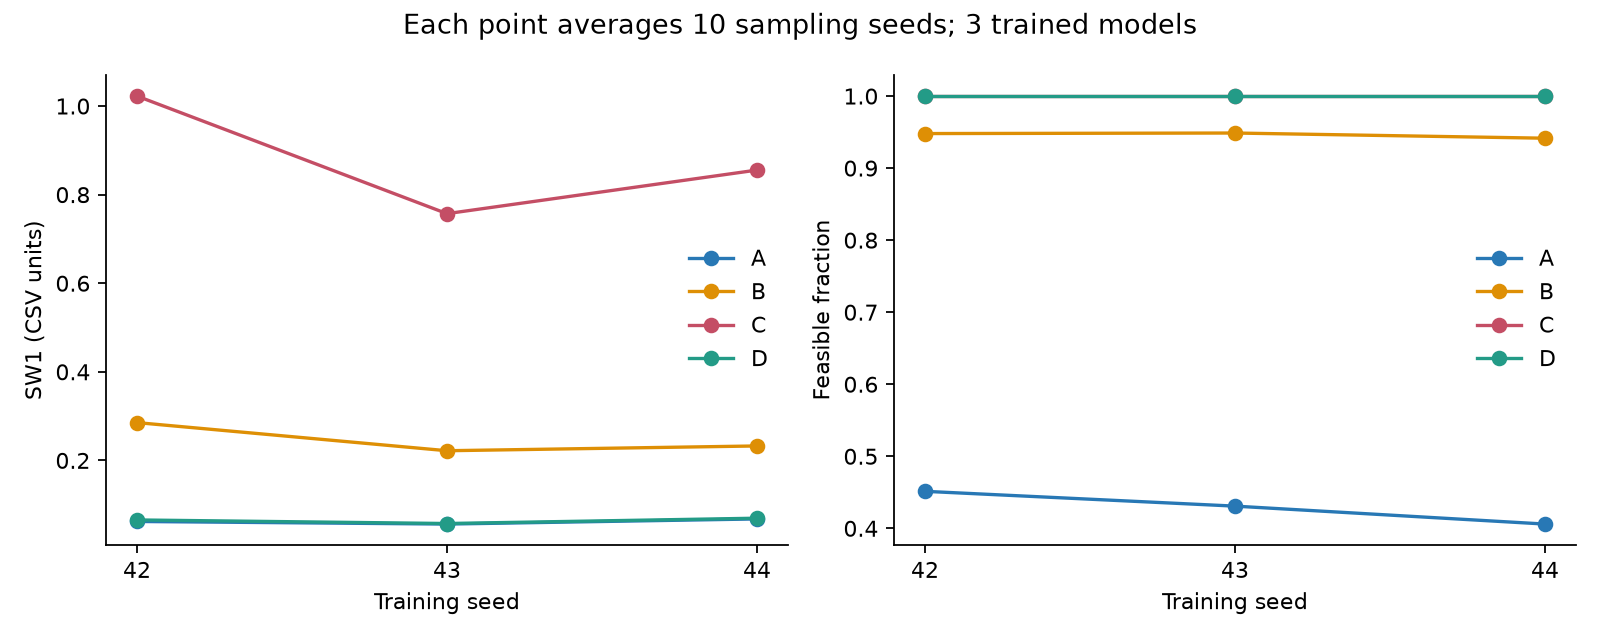

In [9]:
# Read the completed extension: validation constraint ablation and separate
# training-seed robustness. This cell does not launch additional training.
manifest = Path("supplementary_run.json")
if manifest.exists():
    extra = Path(json.loads(manifest.read_text())["run_dir"])
    protocol = json.loads((extra / "protocol.json").read_text())
    if Path(protocol["base_run"]).resolve() == out.resolve():
        print("Supplementary run:", extra.as_posix())
        show_table(pd.read_csv(extra / "per_training_seed.csv").set_index(["training_seed", "method"]),
                   "Training robustness · each row averages 10 sampling seeds; feasibility is a fraction")
        show_table(pd.read_csv(extra / "paired_training_means.csv").set_index("training_seed"),
                   "Paired SW1 differences · one mean per independently trained model")
        # Refresh presentation from recorded tables; no sampling or training.
        from supplementary_experiments import plot_supplement, plot_training_robustness
        plot_supplement(extra, pd.read_csv(extra / "ablation_metrics.csv"),
                        pd.read_csv(extra / "trajectories.csv"),
                        pd.read_csv(extra / "training_path_diagnostic.csv"))
        plot_training_robustness(extra, pd.read_csv(extra / "per_training_seed.csv")
                                 .set_index(["training_seed", "method"]))
        from IPython.display import Image
    
        for name in ["trajectories.png", "ablation.png", "training_robustness.png"]:
            display(Image(filename=str(extra / name), width=1000))
    else:
        print("Skipping supplementary results: they belong to a different primary run. Analyse the documented run or rerun the extension for its supported seed-42 protocol.")

else:
    print("Run python supplementary_experiments.py to produce the optional extension.")

## Fixed-count timing experiment

The original C–D comparison changes both projection timing and the number of
projection calls. This follow-up holds the count fixed and changes their placement:

| Schedule | Post-Euler projection steps | Calls |
|:--|:--|--:|
| A | None | 0 |
| D | 100 only | 1 |
| C | 1–100 | 100 |
| Early25 | 1–24 and 100 | 25 |
| Late25 | 76–100 | 25 |

**The controlled timing contrast is Late25 versus Early25.** Both use the same
hard projection and include the endpoint, with 100 Euler steps, shared initial
noise and a common validation reference within each sampling seed. We reuse
training seeds 42, 43 and 44, with ten sampling seeds and 2,000 profiles per
schedule and seed. No model is retrained and no schedule is selected by test
performance. `schedule_experiments.py` generates this experiment explicitly;
Run All below only reads the completed measurements and refreshes the figures.

The two disjoint validation reference subsets per seed differ from the test
references in the primary tables and from the earlier ablation's reference
sampling. Compare schedules **within this experiment**, not raw SW1 values
across those tables. This remains exploratory follow-up after inspection of
historical test results, rather than an independent confirmatory study.

Completed schedule experiment: outputs/schedules/run_20261013_122906_531017


,mean,std
training_seed,,
42,-0.9465,0.0192
43,-0.6954,0.0201
44,-0.7847,0.0240


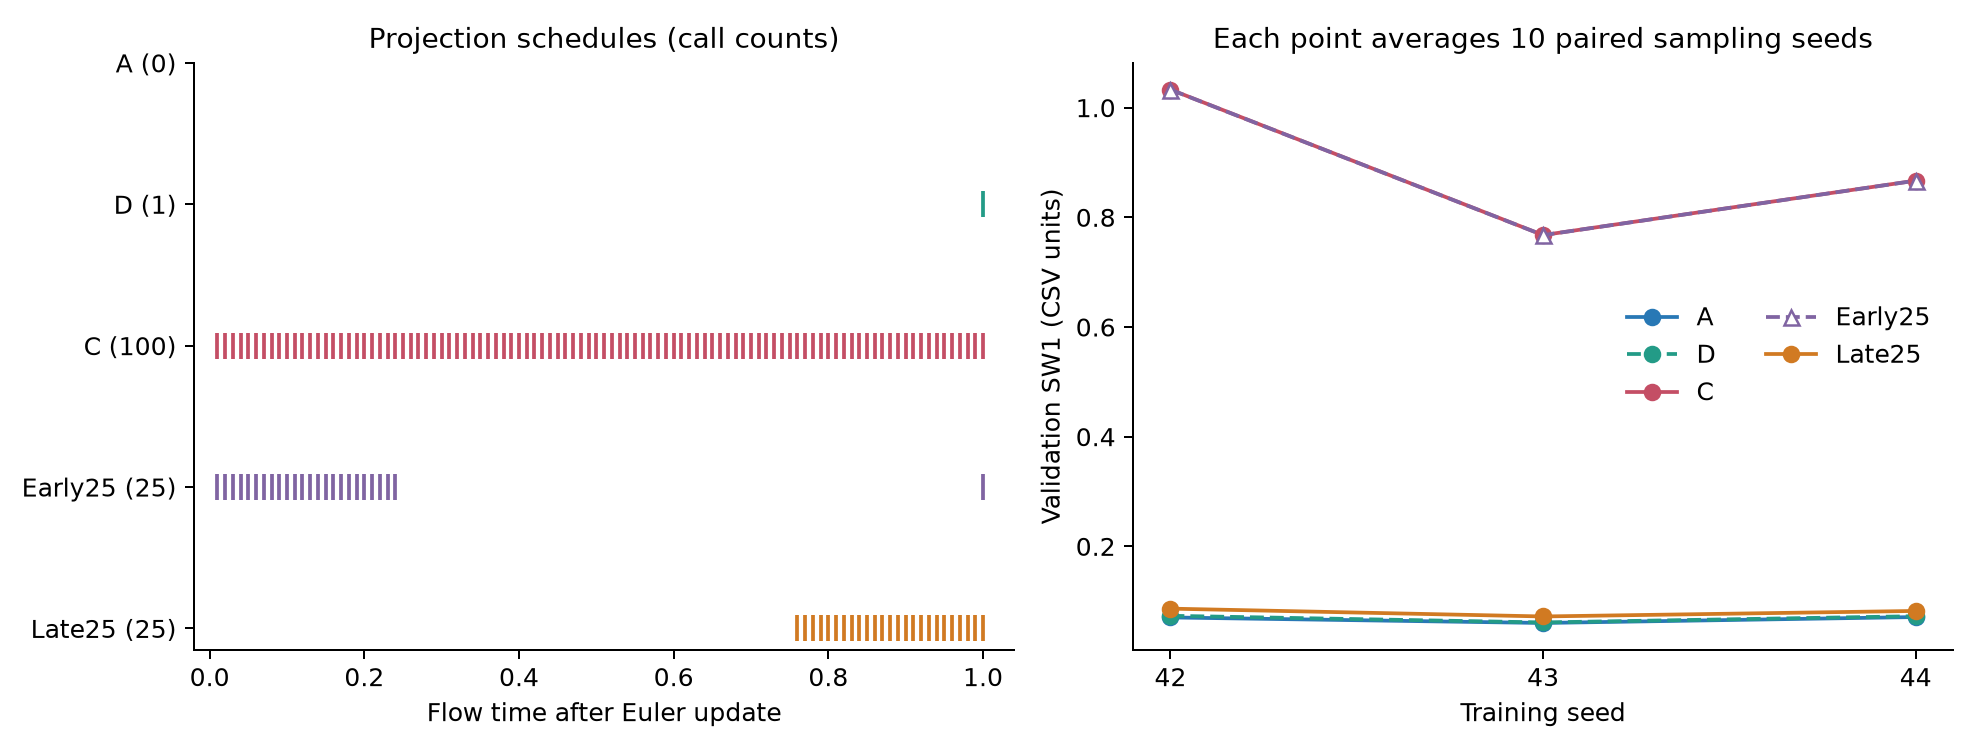

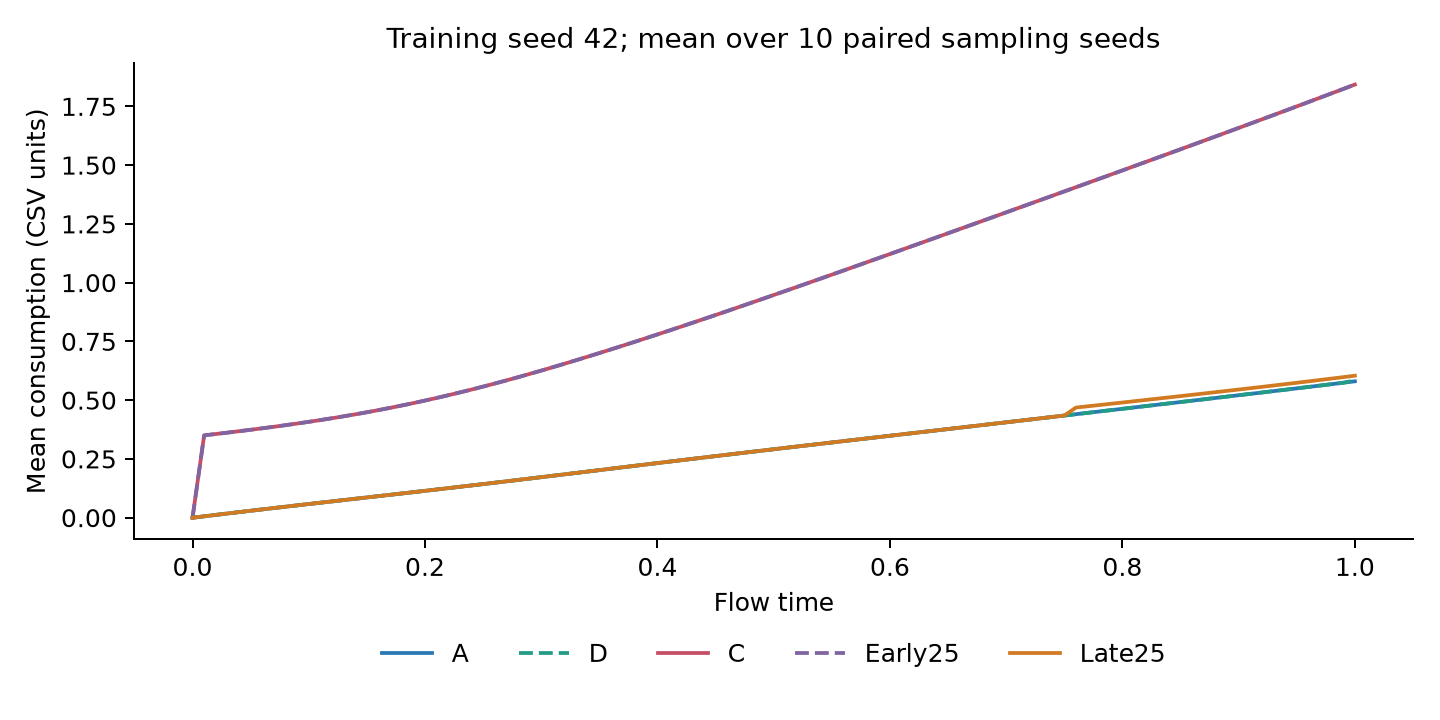

In [10]:
# Load only complete results associated with the selected primary experiment.
# Each displayed SD is across ten paired sampling/reference seeds within one model.
from schedule_experiments import plot_schedules, paired_differences
from IPython.display import Image

schedule_manifest = Path("schedule_run.json")
schedule_frame = None
if schedule_manifest.exists():
    schedule_out = Path(json.loads(schedule_manifest.read_text())["run_dir"])
    schedule_protocol = json.loads((schedule_out / "protocol.json").read_text())
    if (schedule_out / "COMPLETE.json").exists() and Path(schedule_protocol["base_run"]).resolve() == out.resolve():
        schedule_frame = pd.read_csv(schedule_out / "metrics.csv")
        print("Completed schedule experiment:", schedule_out.as_posix())
        timing_table = schedule_frame.groupby(["training_seed", "method"])[
            ["feasible_fraction", "sliced_w1", "daily_total_w1"]].mean()
        show_table(timing_table, "Validation means · 10 sampling seeds per model; feasibility is a fraction")
        timing_paired = paired_differences(schedule_frame)
        show_table(timing_paired.groupby("training_seed")["sliced_w1"].agg(["mean", "std"]),
                   "Paired SW1: Late25 − Early25 · negative values favour late placement")
        plot_schedules(schedule_out, schedule_frame,
                       pd.read_csv(schedule_out / "trajectories.csv"))
        for name in ["schedule_comparison.png", "schedule_trajectories.png"]:
            display(Image(filename=str(schedule_out / name), width=1000))
    else:
        print("Skipping incomplete schedule results or results from another primary run.")
else:
    print("Run python schedule_experiments.py to create the fixed-count comparison.")

In [11]:
# Derive the interpretation from the active result table; avoid stale copied values.
if schedule_frame is not None:
    timing_means = schedule_frame.groupby(["training_seed", "method"]).sliced_w1.mean().unstack()
    timing_delta = timing_means["Late25"] - timing_means["Early25"]
    all_feasible = schedule_frame[schedule_frame.method.isin(["Early25", "Late25"])].feasible_fraction.eq(1).all()
    display(Markdown(
        f"**Controlled timing result:** Late25 has lower mean validation SW1 than Early25 "
        f"in **{int((timing_delta < 0).sum())} of {len(timing_delta)} trained models**. "
        f"Both schedules attain 100% numerical feasibility in every evaluated seed: **{all_feasible}**. "
        "The fixed-count contrast supports an effect of projection placement in these settings. "
        "It does not establish an optimal schedule, isolate every intermediate time, or prove "
        "that terminal projection is universally best. The sampling seeds describe variation "
        "within a fitted model; there are three trained models, not thirty independent trainings."
    ))

**Controlled timing result:** Late25 has lower mean validation SW1 than Early25 in **3 of 3 trained models**. Both schedules attain 100% numerical feasibility in every evaluated seed: **True**. The fixed-count contrast supports an effect of projection placement in these settings. It does not establish an optimal schedule, isolate every intermediate time, or prove that terminal projection is universally best. The sampling seeds describe variation within a fitted model; there are three trained models, not thirty independent trainings.